# Problem 02 - Captum; Test Case Generator

**This notebook is used for generating test cases. There is no need to touch it as a student!**

**No work in this notebook will be graded. Running this notebook as a student may break the test cases in the quiz and prevent auto-grading from succeeding.**

## Imports

In [2]:
import torch

# Model building
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR

# Data loading
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2

# Interpretability
from captum.attr import Saliency

# Python
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt


torch.manual_seed(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data

In [3]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

dataset = datasets.MNIST(
    root="./assignment/example_data", download=True, transform=transform
)

## Train Test Split

In [4]:
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [train_size, test_size]
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Fit Model

In [5]:
@dataclass
class TrainingParameters:
    """Training parameters for a simple neural network trainer."""

    epochs: int = 3
    lr: float = 1.0
    gamma: float = 0.7
    dry_run: bool = False
    seed: int = 1
    save_model: bool = True


def predict(model, device, test_loader):
    """Make inferences using a given model and device, on a test set."""
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction="sum").item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print(
        "\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n".format(
            test_loss,
            correct,
            len(test_loader.dataset),
            100.0 * correct / len(test_loader.dataset),
        )
    )


def run_training_epoch(
    training_params, model, device, train_loader, optimizer, epoch
):
    """Execute a single training epoch."""
    model.train()
    for batch_index, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if training_params.dry_run:
            break
        if batch_index % round(len(train_loader) / 79 + 1) == 0:
            print(".", end="")
    print("")
    print("Train Epoch: {} \tLoss: {:.6f}".format(epoch, loss.item()))

    if training_params.save_model:
        torch.save(model.state_dict(), "./assignment/models/mnist_cnn.pt")


def train(model, training_params, device, train_loader, test_loader):
    """Cycle through epochs to train the given model."""
    optimizer = optim.Adadelta(model.parameters(), lr=training_params.lr)
    scheduler = StepLR(optimizer, step_size=1, gamma=training_params.gamma)

    for epoch in range(1, training_params.epochs + 1):
        run_training_epoch(
            training_params, model, device, train_loader, optimizer, epoch
        )
        predict(model, device, test_loader)
        scheduler.step()


class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        y = F.log_softmax(x, dim=1)
        return y


model = SimpleCNN().to(device)
training_params = TrainingParameters(epochs=1, dry_run=False)
train(model, training_params, device, train_loader, test_loader)

...........................................................................
Train Epoch: 1 	Loss: 0.105164

Test set: Average loss: 0.0735, Accuracy: 11710/12000 (98%)



## Save Model

In [6]:
model_scripted = torch.jit.script(model)
torch.jit.save(model_scripted, "./assignment/models/model.pth")

## Load Model

In [7]:
model = torch.jit.load("./assignment/models/model.pth")
model.eval()

RecursiveScriptModule(
  original_name=SimpleCNN
  (conv1): RecursiveScriptModule(original_name=Conv2d)
  (conv2): RecursiveScriptModule(original_name=Conv2d)
  (dropout1): RecursiveScriptModule(original_name=Dropout)
  (dropout2): RecursiveScriptModule(original_name=Dropout)
  (fc1): RecursiveScriptModule(original_name=Linear)
  (fc2): RecursiveScriptModule(original_name=Linear)
)

## Obtain a Test Image

In [8]:
test_images, test_labels = next(iter(test_loader))
test_image = test_images[10]
test_image_array = test_image.detach().numpy()
np.save(
    "./tests/test_data/problem_02_test_image.npy",
    test_image_array,
)

# Obtain Attributions on Test Image

In [9]:
from assignment.problem_02 import problem_02

expected_attribution_array: np.ndarray = problem_02()
np.save(
    "./tests/test_data/problem_02_expected_attribution.npy",
    expected_attribution_array,
)

## Visualize the Results

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

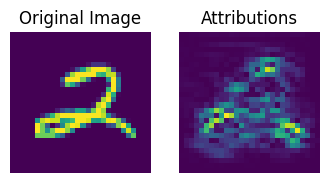

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(4, 3))
ax[0].imshow(test_image_array.transpose(1, 2, 0))
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(expected_attribution_array)
ax[1].set_title("Attributions")
ax[1].axis("off")